# XGBoost baseline

XGBoost and Random Forest use the same full training/development cohorts and 224 KPI features. The runner verifies IDs, labels, feature order, fitted medians, and feature matrices against the saved RF run.

Training weights are `N / (K * class_count)` from training labels only. Early stopping uses unweighted dev log loss (binary) or multiclass log loss, with 30 rounds of patience and a 500-round cap. Configuration selection uses dev macro-F1 at the loss-best iteration. Both tasks use CPU histogram training and one thread.

These local results are exploratory: recording independence remains unresolved. Install notebook/model tools with `uv sync --extra dev --extra analysis --extra baselines`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from clauseguard.datasets.scenarios import ScenarioDataset
from clauseguard.baselines.xgboost import run_xgboost, predict_saved_model

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_ROOT = ROOT
RELEASE = DATA_ROOT / "data/scenarios/release"
RF_REFERENCE = DATA_ROOT / "artifacts/experiments/rf-all-data-provisional-2026-10-19"
TRAIN_OUTPUT = DATA_ROOT / "artifacts/experiments/xgboost-full-data-2026-10-19"

## Training

Four configurations: depth 3/6 × minimum child weight 1/5. Minimum child weight measures Hessian mass, not a minimum number of rows. The selected seed-42 run is reused; seeds 43/44 repeat that configuration with their own dev stopping iteration. Full row/column sampling can produce identical seed results.

In [2]:
RUN_TRAINING = False
NEW_TRAIN_OUTPUT = DATA_ROOT / "artifacts/experiments/xgboost-notebook-new-run"
if RUN_TRAINING:
    training = run_xgboost(
        ScenarioDataset(RELEASE, allow_exploratory=True), NEW_TRAIN_OUTPUT,
        rf_reference=RF_REFERENCE, allow_exploratory=True,
    )
    display(training)
selection = json.loads((TRAIN_OUTPUT / "selection.json").read_text())
rf_selection = json.loads((RF_REFERENCE / "selection.json").read_text())
print("Release:", selection["release_id"])
print("Evaluation:", selection["evaluation_status"])

Release: f3bd4d46bb04363adbecd0e3106767f179c560815b09fdf6309aaf013fc0b784
Evaluation: provisional_exploratory


## Development comparison

Scores use all dev windows: 6,590 for detection and 177 for category. No dev/test windows fit the medians or training weights. The table reports seed variation, selected boosting rounds, and fit time. Memory metadata is the process-wide high-water mark, not an isolated model peak.

In [3]:
development = []
for task, result in selection["tasks"].items():
    runs = [json.loads((TRAIN_OUTPUT / seed["run"] / "run.json").read_text())
            for seed in result["selected_seeds"]]
    development.append({
        "task": task, "train_windows": result["train_windows"],
        "configuration": result["selected_configuration"],
        "RF dev macro-F1": rf_selection["tasks"][task]["dev_macro_f1_mean"],
        "XGB dev macro-F1": result["dev_macro_f1_mean"],
        "XGB seed SD": result["dev_macro_f1_std"],
        "retained rounds": [run["configuration"]["retained_rounds"] for run in runs],
        "fit seconds": [round(run["resources"]["fit_seconds"], 3) for run in runs],
    })
display(pd.DataFrame(development))

,task,train_windows,configuration,RF dev macro-F1,XGB dev macro-F1,XGB seed SD,retained rounds,fit seconds
0,category,563,"{'max_depth': 6, 'min_child_weight': 5}",0.569413,0.517595,0.0,"[271, 271, 271]","[1.891, 1.881, 1.927]"
1,detection,19089,"{'max_depth': 6, 'min_child_weight': 5}",0.660828,0.882403,0.0,"[127, 127, 127]","[2.436, 2.558, 2.304]"


## Training data head

One row is one 128-sample KPI window summarized into 224 features. The target and origin columns below are inspection metadata; they are not model features. The checkpoint reload uses its saved medians and feature order.

In [4]:
from itertools import islice
from clauseguard.baselines.artifacts import load_run
from clauseguard.kpi.features import ChannelMedianFeatures
from clauseguard.kpi.xgboost import load_model

TASK = "detection"
MODEL_RUN = TRAIN_OUTPUT / selection["tasks"][TASK]["selected_seeds"][0]["run"]
saved = load_run(MODEL_RUN)
meta = saved["metadata"]
features = ChannelMedianFeatures()
features.feature_names_ = tuple(meta.transformations["feature_order"])
features.medians_ = np.asarray(meta.transformations["channel_medians"])
model = load_model(MODEL_RUN / "model.ubj", expected_sha256=meta.checkpoint,
                   task=TASK, features=features,
                   configuration={k: meta.configuration[k] for k in ("max_depth", "min_child_weight")},
                   seed=meta.seed)
dataset = ScenarioDataset(RELEASE, allow_exploratory=True)
examples = list(islice(dataset.iter_examples(split="train", task=TASK), 5))
values = features.transform([e.inputs for e in examples])
columns = ["DL_BLER__mean", "DL_BLER__max", "PRB_Utilization_DL__mean", "RSRP__mean", "UL_SNR__mean"]
head = pd.DataFrame(values[:, [features.feature_names_.index(c) for c in columns]], columns=columns)
head.insert(0, "target", [e.target for e in examples])
head.insert(0, "scenario_id", [e.scenario_id[:18] + "…" for e in examples])
display(head)
print("Feature count:", len(features.feature_names_))
print("Matched RF checkpoint:", meta.transformations["reference_rf_checkpoint"])

,scenario_id,target,DL_BLER__mean,DL_BLER__max,PRB_Utilization_DL__mean,RSRP__mean,UL_SNR__mean
0,telecomts-00095e76…,0,0.000070,0.000170,0.005163,-88.000000,21.052031
1,telecomts-000d22a6…,0,0.000008,0.000040,0.007375,-87.184083,21.606016
2,telecomts-000dea30…,0,0.000000,0.000000,2.155812,-112.031252,20.607500
3,telecomts-000f2450…,0,0.000000,0.000000,1.599416,-87.508765,20.740508
4,telecomts-000f68a9…,0,0.137077,0.334055,16.668475,-119.249394,20.098945


Feature count: 224
Matched RF checkpoint: a94b67ffa162cbd348a2b95c0fe249b37e3cfc9e3761da237fdab210adf5aeff


## Dev loss during boosting

Dots mark the loss-best iteration. Configurations are compared by macro-F1 at those checkpoints, rather than selecting a different round on macro-F1. Loss histories also show whether the 500-round budget was reached.

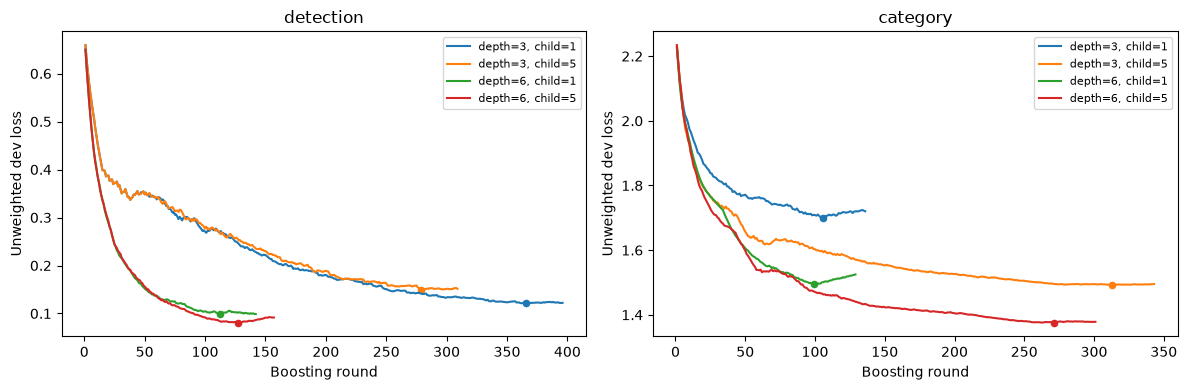

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, task in zip(axes, ("detection", "category")):
    for trial in selection["tasks"][task]["trials"]:
        run = json.loads((TRAIN_OUTPUT / trial["run"] / "run.json").read_text())
        config = run["configuration"]
        losses = config["training_history"]
        label = f"depth={config['max_depth']}, child={config['min_child_weight']}"
        line, = axis.plot(np.arange(1, len(losses) + 1), losses, label=label)
        best = config["best_iteration"]
        axis.scatter([best + 1], [losses[best]], color=line.get_color(), s=20)
    axis.set(title=task, xlabel="Boosting round", ylabel="Unweighted dev loss")
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(TRAIN_OUTPUT / "development_loss.png", dpi=160)
plt.show()

## Test results and errors

These are separate seed-42 checkpoint predictions on the full test cohorts. Settings were selected on dev. The existing TelecomTS test has already been inspected in exploratory work, so this comparison is not a new untouched holdout. Read recall, false alarms, and source breakdowns alongside accuracy.

In [6]:
test_results = []
for task in ("detection", "category"):
    for name, root in (("RF", RF_REFERENCE), ("XGBoost", TRAIN_OUTPUT)):
        metrics = json.loads((root / task / "test-seed-42/metrics.json").read_text())
        test_results.append({"task": task, "model": name, "windows": metrics["count"],
                             "accuracy": metrics["accuracy"], "macro-F1": metrics["macro_f1"],
                             "fault recall": metrics.get("recall"),
                             "false alarms": metrics.get("false_alarms"),
                             "missed faults": metrics.get("missed_faults")})
display(pd.DataFrame(test_results))

members = dataset.splits["membership"]
origin_results = []
for name, root in (("RF", RF_REFERENCE), ("XGBoost", TRAIN_OUTPUT)):
    path = root / "detection/test-seed-42"
    expected = json.loads((path / "targets.json").read_text())["expected"]
    with (path / "predictions.jsonl").open() as stream:
        predictions = {row["scenario_id"]: row["predicted_label"] for row in map(json.loads, stream)}
    for origin in ("normal", "synthetic", "real"):
        ids = [sid for sid in expected if members[sid]["origin"] == origin]
        positive = [sid for sid in ids if expected[sid] == 1]
        caught = sum(predictions[sid] == 1 for sid in positive)
        origin_results.append({"model": name, "origin": origin, "windows": len(ids),
                               "faults caught": caught, "faults missed": len(positive) - caught,
                               "false alarms": sum(expected[sid] == 0 and predictions[sid] == 1 for sid in ids)})
display(pd.DataFrame(origin_results))
category = json.loads((TRAIN_OUTPUT / "category/test-seed-42/metrics.json").read_text())
labels = {str(value): key for key, value in json.loads((RELEASE / "labels.json").read_text())["category"].items()}
display(pd.DataFrame([{"class": labels[label], **metrics} for label, metrics in category["per_class"].items()]))

,task,model,windows,accuracy,macro-F1,fault recall,false alarms,missed faults
0,detection,RF,6321,0.961240,0.663347,0.210356,1.0,244.0
1,detection,XGBoost,6321,0.987344,0.925261,0.776699,11.0,69.0
2,category,RF,216,0.310185,0.223574,NaN,NaN,NaN
3,category,XGBoost,216,0.495370,0.352102,NaN,NaN,NaN


,model,origin,windows,faults caught,faults missed,false alarms
0,RF,normal,6012,0,0,1
1,RF,synthetic,216,63,153,0
2,RF,real,93,2,91,0
3,XGBoost,normal,6012,0,0,11
4,XGBoost,synthetic,216,150,66,0
5,XGBoost,real,93,90,3,0


,class,f1,precision,recall,support
0,Antenna Failure,0.521739,0.428571,0.666667,9
1,Co-Channel Interference (Mild),0.273973,0.192308,0.476190,21
2,Co-Channel Interference (Severe),0.764706,0.750000,0.780000,50
3,Faulty RF Filters (Temporal),0.400000,0.461538,0.352941,17
4,Doppler Shift (Severe),0.720000,0.562500,1.000000,18
5,Faulty Handover Algorithm (Too Frequent),0.000000,0.000000,0.000000,12
6,Buffer Overflow (Gradual Buildup),0.227273,0.714286,0.135135,37
7,Resource Allocation Bugs,0.000000,0.000000,0.000000,10
8,High Network Congestion (Gradual Buildup),0.613333,0.522727,0.741935,31
9,High Network Congestion (Sudden Spike),0.000000,0.000000,0.000000,11


## Reloaded prediction and CLI

`MODEL_RUN` is the selected detection seed-42 checkpoint above. Enable prediction only with a new output directory. Reloading preserves the chosen rounds, medians, feature names and class mapping.

```bash
uv run python -m clauseguard.cli.xgboost train --task both --allow-exploratory --release-dir data/scenarios/release --rf-reference artifacts/experiments/rf-all-data-provisional-2026-10-19 --output-dir artifacts/experiments/xgboost-new-run
uv run python -m clauseguard.cli.xgboost predict --allow-exploratory --release-dir data/scenarios/release --model-run-dir PATH_TO_SELECTED_RUN --output-dir artifacts/experiments/xgboost-new-prediction
```

In [7]:
RUN_HELDOUT_PREDICTION = False
TEST_OUTPUT = DATA_ROOT / "artifacts/experiments/xgboost-notebook-test-new-run"
if RUN_HELDOUT_PREDICTION:
    metrics = predict_saved_model(dataset, MODEL_RUN, TEST_OUTPUT, allow_exploratory=True)
    display({key: metrics[key] for key in ("count", "accuracy", "macro_f1", "recall", "missed_faults")})